<a href="https://colab.research.google.com/github/HMasaru/Mini-Projeto-IA-ML-Cluster/blob/main/Mini%20Projeto%20IA%20ML%20Cluster.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# LAB - Mini Projeto: IA ML Cluster

**Dupla:**
* Hélio Masaru Sueta
* Pedro Vianna

**Detalhes do Projeto:**
* **Dataset Escolhido:** Spotify Tracks Dataset
* **Modelo Utilizado:** K-Means
* **Objetivo:** Agrupar músicas com base em suas características sonoras


In [13]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

# Carregando o dataset (certifique-se de que o nome do arquivo está correto)
df = pd.read_csv('spotify-tracks-dataset.csv')

# Removendo valores nulos para evitar erros no Scikit-Learn
df = df.dropna()

print("Formato do dataset:", df.shape)
display(df.head())

Formato do dataset: (113999, 22)


,Unnamed: 0.1,Unnamed: 0,track_id,artists,album_name,track_name,popularity,duration_ms,explicit,danceability,...,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature,track_genre
0,0,0,5SuOikwiRyPMVoIQDJUgSV,Gen Hoshino,Comedy,Comedy,73,230666,False,0.676,...,-6.746,0,0.1430,0.0322,0.000001,0.3580,0.715,87.917,4,acoustic
1,1,1,4qPNDBW1i3p13qLCt0Ki3A,Ben Woodward,Ghost (Acoustic),Ghost - Acoustic,55,149610,False,0.420,...,-17.235,1,0.0763,0.9240,0.000006,0.1010,0.267,77.489,4,acoustic
2,2,2,1iJBSr7s7jYXzM8EGcbK5b,Ingrid Michaelson;ZAYN,To Begin Again,To Begin Again,57,210826,False,0.438,...,-9.734,1,0.0557,0.2100,0.000000,0.1170,0.120,76.332,4,acoustic
3,3,3,6lfxq3CG4xtTiEg7opyCyx,Kina Grannis,Crazy Rich Asians (Original Motion Picture Sou...,Can't Help Falling In Love,71,201933,False,0.266,...,-18.515,1,0.0363,0.9050,0.000071,0.1320,0.143,181.740,3,acoustic
4,4,4,5vjLSffimiIP26QG5WcN2K,Chord Overstreet,Hold On,Hold On,82,198853,False,0.618,...,-9.681,1,0.0526,0.4690,0.000000,0.0829,0.167,119.949,4,acoustic


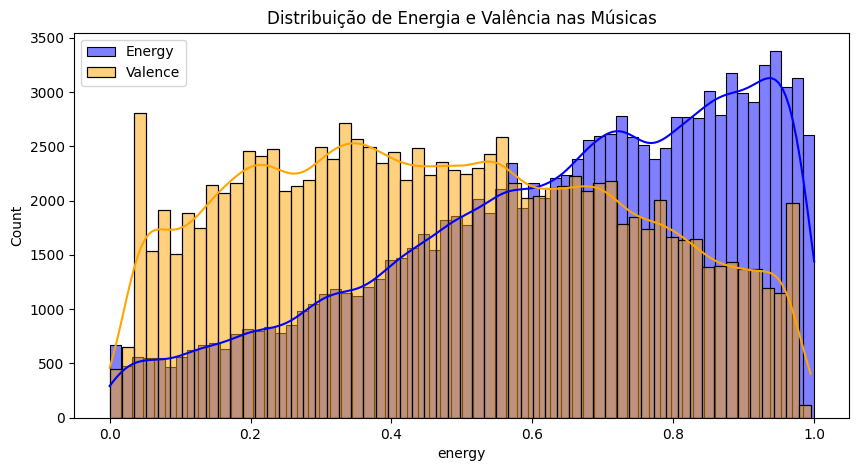

In [12]:
#Análise Exploratória (EDA) Básica

plt.figure(figsize=(10, 5))
sns.histplot(df['energy'], color='blue', kde=True, label='Energy', alpha=0.5)
sns.histplot(df['valence'], color='orange', kde=True, label='Valence', alpha=0.5)
plt.title('Distribuição de Energia e Valência nas Músicas')
plt.legend()
plt.show()

In [11]:
# Preparação dos Dados para o K-Means

features = ['danceability', 'energy', 'loudness', 'speechiness',
            'acousticness', 'instrumentalness', 'liveness', 'valence', 'tempo']

X = df[features]

# Padronização (StandardScaler)
# O K-Means calcula distâncias, então precisamos deixar todas as features na mesma escala
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

In [9]:
# Aplicando o K-Means
# Vamos assumir 4 clusters (ex: Músicas calmas, Músicas agitadas/felizes, Músicas de festa, Músicas acústicas)
k = 4
kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)

# Treinando o modelo e criando a coluna de clusters no DataFrame original
df['Cluster'] = kmeans.fit_predict(X_scaled)

print(f"Músicas agrupadas em {k} clusters com sucesso!")
print(df['Cluster'].value_counts())

Músicas agrupadas em 4 clusters com sucesso!
Cluster
2    47116
3    34739
1    23433
0     8711
Name: count, dtype: int64


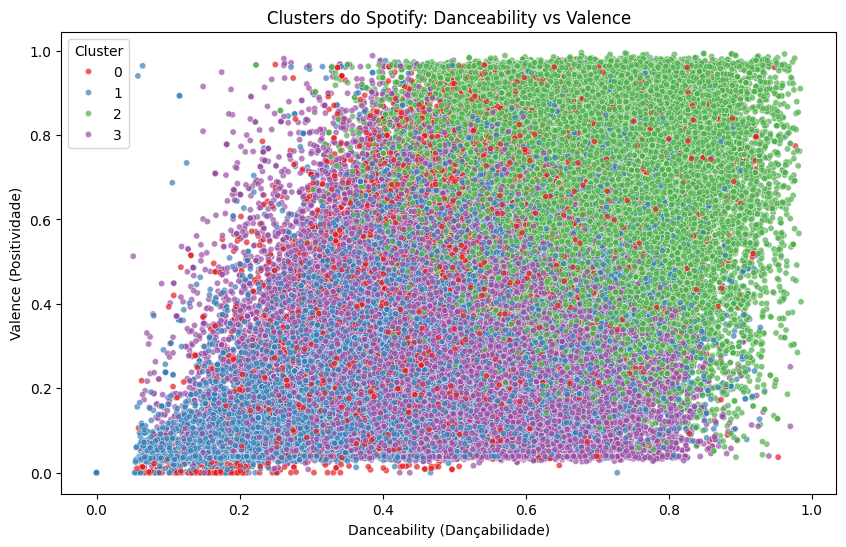

In [10]:
# Visualizando o Resultado
# Gráfico de Dispersão: Danceability vs Valence (Quão dançante vs Quão feliz/positiva)
plt.figure(figsize=(10, 6))
sns.scatterplot(x=df['danceability'], y=df['valence'], hue=df['Cluster'], palette='Set1', s=20, alpha=0.7)
plt.title('Clusters do Spotify: Danceability vs Valence')
plt.xlabel('Danceability (Dançabilidade)')
plt.ylabel('Valence (Positividade)')
plt.legend(title='Cluster')
plt.show()